# 01 – Exploratory Data Analysis: SCANIA Component X

**Goal of this notebook:** understand the SCANIA data *before* any model is trained.
Every later decision (labels, split, features, metrics, leakage tests) is based on what we
find here.

**Questions this notebook answers**

| # | Question | Why it matters later |
|---|----------|----------------------|
| 1 | What do the tables look like, and how are they connected? | Joins, keys, data contract (pandera) |
| 2 | Are the official splits clean (no truck in two splits)? | Data leakage |
| 3 | Which columns are counters and which are histograms? | Feature engineering |
| 4 | How many trucks were repaired? How long were they observed? | Target, imbalance, censoring |
| 5 | How is `time_step` distributed? How often do trucks send readouts? | Label construction |
| 6 | Where are missing values? | Imputation |
| 7 | Do counters only grow? Are there resets? | Feature engineering, data quality |
| 8 | What do histograms contain? | Feature engineering |
| 9 | Do the truck specifications differ between splits? | Data drift |
| 10 | How many readouts get class 0–4, how many are unknown (censored)? | `labels.py` tomorrow |

**Sources:** the dataset paper (`data/raw/scania/Scania_Component_X.pdf`, Kharazian et al.,
*Scientific Data* 2025) and the challenge description (`data/raw/scania/2024_IDA_challenge_v2.pdf`).
Statements marked *(paper)* come from there; this notebook checks them on the real data.

**How to run:** open the repo folder in VS Code (WSL), select the kernel
`.venv/bin/python` of **failsense**, run `make data` and `make parquet` once, then
*Run All*.

> Rule for this notebook: **explore, do not build the product here.** Code that the model
> needs (labels, splits, features) moves to `src/failsense/` with tests.

## 0. Setup

We import the libraries, configure how pandas and matplotlib display things, and load all
paths from `configs/config.yaml` through our own module `failsense.config` –
**no hardcoded paths**.

In [1]:
# --- Standard library -------------------------------------------------------
import re  # regular expressions: split column names like "167_3" into variable and bin
import time  # measure how long loading takes
from pathlib import Path  # paths as objects, works on Linux and Windows

# --- Third-party ------------------------------------------------------------
import matplotlib.pyplot as plt  # plots
import numpy as np  # numerical arrays
import pandas as pd  # tables (DataFrames)

# --- Our own package (installed in editable mode by `uv sync`, see ADR 0002) -
from failsense.config import find_repo_root, load_config, resolve_path

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


In [2]:
# How pandas prints tables in the notebook ----------------------------------------
pd.set_option("display.max_columns", 120)  # show all 107 columns instead of "..."
pd.set_option("display.width", 200)  # wider lines before pandas wraps
pd.set_option("display.float_format", "{:,.2f}".format)  # 1234567.891 -> 1,234,567.89

# How matplotlib draws figures ------------------------------------------------------
plt.rcParams["figure.figsize"] = (10, 4)  # default size in inches (width, height)
plt.rcParams["axes.grid"] = True  # light grid helps reading values
plt.rcParams["axes.spines.top"] = False  # remove the top and right frame lines
plt.rcParams["axes.spines.right"] = False

RNG = np.random.default_rng(42)  # one random generator with a fixed seed -> reproducible samples

In [3]:
# Paths from the central config -----------------------------------------------------
ROOT = find_repo_root()
config = load_config()
scania_cfg = config["datasets"]["scania"]

PROCESSED_DIR = resolve_path(scania_cfg["processed_dir"])
FIGURE_DIR = ROOT / config["paths"]["reports"] / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)  # create reports/figures if missing


def parquet_path(split: str, table: str) -> Path:
    # The Parquet file has the same name as the CSV in the config, only another suffix
    csv_path = Path(scania_cfg[split][table])
    return PROCESSED_DIR / f"{csv_path.stem}.parquet"


def save_figure(fig, name: str) -> None:
    # Figure names start with the notebook number, so a reviewer knows where they come from
    path = FIGURE_DIR / f"01_eda_scania_{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


print("repo root   :", ROOT)
print("parquet from:", PROCESSED_DIR.relative_to(ROOT))
print("example     :", parquet_path("train", "tte").name)

repo root   : /home/danee/projects/failsense
parquet from: data/processed/scania
example     : train_tte.parquet


## 1. Load the data

SCANIA delivers **three kinds of tables** per split. Think of them like tables in SQL
Server, connected by the key `vehicle_id`:

| Table | Like in an ERP system | One row per … |
|-------|------------------------|---------------|
| `operational_readouts` | transactions / movements | **readout** (many rows per truck) |
| `tte` (train only) / `labels` (validation, test) | events / results | **truck** |
| `specifications` | master data | **truck** |

We load the Parquet copies (`make parquet`). Reading Parquet is faster, keeps the column
types, and can read only selected columns.

In [4]:
def load(split: str, table: str, columns: list[str] | None = None) -> pd.DataFrame:
    # Load one table; `columns=None` means all columns
    start = time.perf_counter()
    df = pd.read_parquet(parquet_path(split, table), columns=columns)
    seconds = time.perf_counter() - start
    print(
        f"{split:<10} {table:<15} {df.shape[0]:>9,} rows x {df.shape[1]:>3} cols  ({seconds:.2f} s)"
    )
    return df


train_readouts = load("train", "readouts")
train_tte = load("train", "tte")
train_spec = load("train", "specifications")

val_readouts = load("validation", "readouts")
val_labels = load("validation", "labels")
val_spec = load("validation", "specifications")

test_readouts = load("test", "readouts")
test_spec = load("test", "specifications")
# test_labels is NOT loaded on purpose: the test set is used exactly once, at the very end.

train      readouts        1,122,452 rows x 107 cols  (0.49 s)
train      tte                23,550 rows x   3 cols  (0.00 s)
train      specifications     23,550 rows x   9 cols  (0.00 s)
validation readouts          196,227 rows x 107 cols  (0.09 s)
validation labels              5,046 rows x   2 cols  (0.00 s)
validation specifications      5,046 rows x   9 cols  (0.00 s)
test       readouts          198,140 rows x 107 cols  (0.09 s)
test       specifications      5,045 rows x   9 cols  (0.00 s)


**Alternative ways to load the same data (for comparison, not needed here):**

```python
# 1) Directly from CSV (slower, pandas guesses the types every time)
pd.read_csv("data/raw/scania/train_tte.csv")

# 2) Only some columns from Parquet (fast, columnar format)
pd.read_parquet(path, columns=["vehicle_id", "time_step", "171_0"])

# 3) With pyarrow directly (lower level, used by pandas internally)
import pyarrow.parquet as pq
pq.read_table(path, columns=["vehicle_id"]).to_pandas()

# 4) With SQL through DuckDB (planned later for the prediction log)
# duckdb.sql("SELECT vehicle_id, COUNT(*) FROM 'train_operational_readouts.parquet' GROUP BY 1")
```

**Why not test labels?** Looking at the test labels during exploration is a quiet form of
data leakage: we would start to make decisions that fit the test set.

## 2. First look at every table

For each table we check the same things – this is a fixed routine in real projects:

1. `shape` – rows and columns
2. `head()` – the first rows
3. `dtypes` – the data type of every column
4. memory usage
5. `describe()` – statistics of numeric columns

In [5]:
# train_tte: one row per truck, the "time to event" information
display(train_tte.head())
print(train_tte.dtypes)

,vehicle_id,length_of_study_time_step,in_study_repair
0,0,510.00,0
1,2,281.80,0
2,3,293.40,0
3,4,210.00,0
4,5,360.40,0


vehicle_id                     int64
length_of_study_time_step    float64
in_study_repair                int64
dtype: object


In [6]:
# train_specifications: one row per truck, 8 categorical columns
display(train_spec.head())
print(train_spec.dtypes)

,vehicle_id,Spec_0,Spec_1,Spec_2,Spec_3,Spec_4,Spec_5,Spec_6,Spec_7
0,0,Cat0,Cat0,Cat0,Cat0,Cat0,Cat0,Cat0,Cat0
1,2,Cat0,Cat1,Cat1,Cat0,Cat0,Cat0,Cat0,Cat1
2,3,Cat0,Cat1,Cat1,Cat1,Cat0,Cat0,Cat0,Cat1
3,4,Cat0,Cat0,Cat2,Cat1,Cat0,Cat0,Cat0,Cat1
4,5,Cat0,Cat2,Cat2,Cat0,Cat0,Cat0,Cat0,Cat1


vehicle_id    int64
Spec_0          str
Spec_1          str
Spec_2          str
Spec_3          str
Spec_4          str
Spec_5          str
Spec_6          str
Spec_7          str
dtype: object


In [7]:
# validation_labels: one row per truck, the class of the LAST readout
display(val_labels.head())
print(val_labels.dtypes)

,vehicle_id,class_label
0,10,0
1,16,0
2,18,0
3,23,0
4,45,0


vehicle_id     int64
class_label    int64
dtype: object


In [8]:
# train_operational_readouts: many rows per truck, 107 columns
display(train_readouts.head())
print(train_readouts.dtypes.value_counts())  # how many columns per data type

,vehicle_id,time_step,171_0,666_0,427_0,837_0,167_0,167_1,167_2,167_3,167_4,167_5,167_6,167_7,167_8,167_9,309_0,272_0,272_1,272_2,272_3,272_4,272_5,272_6,272_7,272_8,272_9,835_0,370_0,291_0,291_1,291_2,291_3,291_4,291_5,291_6,291_7,291_8,291_9,291_10,158_0,158_1,158_2,158_3,158_4,158_5,158_6,158_7,158_8,158_9,100_0,459_0,459_1,459_2,459_3,459_4,459_5,459_6,459_7,459_8,459_9,459_10,459_11,459_12,459_13,459_14,459_15,459_16,459_17,459_18,459_19,397_0,397_1,397_2,397_3,397_4,397_5,397_6,397_7,397_8,397_9,397_10,397_11,397_12,397_13,397_14,397_15,397_16,397_17,397_18,397_19,397_20,397_21,397_22,397_23,397_24,397_25,397_26,397_27,397_28,397_29,397_30,397_31,397_32,397_33,397_34,397_35
0,0,11.20,"167,985.00","10,787.00","7,413,813.00","2,296.00","4,110.00","1,296,420.00","1,628,265.00","630,345.00","1,269,525.00","4,772,940.00","2,706,706.00","222,225.00","6,240.00",0.00,70.00,"1,435,083.00","857,662.00","384,579.00","668,642.00","7,239,843.00","398,490.00","3,887.00",0.00,0.00,0.00,"8,036,751.00",0.00,"1,227.00",555.00,463.00,925.00,468.00,225.00,535.00,516.00,492.00,729.00,66.00,"97,056.00","2,690,052.00","2,945,268.00","788,437.00","687,480.00","595,164.00","491,232.00","532,932.00","809,628.00","505,693.00","858,410.00",203.68,111.91,147.27,200.48,230.31,277.72,315.75,372.16,864.25,920.88,637.90,744.62,880.87,"1,272.32","1,847.62",940.79,2.90,0.21,0.06,0.06,"446,956.00","411,420.00","203,024.00","26,636.00","29,156.00","7,616.00","449,537.00","233,352.00","139,920.00","12,648.00","2,813.00",224.00,"53,161.00","178,881.00","138,250.00","13,328.00","3,581.00",88.00,"16,361.00","131,601.00","116,541.00","13,506.00","2,856.00",48.00,"6,337.00","105,412.00","95,728.00","15,609.00","1,984.00",8.00,784.00,"150,228.00","261,904.00","93,172.00","17,874.00",452.00
1,0,11.40,"167,985.00","10,787.00","7,413,813.00","2,296.00","4,111.00","1,302,855.00","1,628,265.00","630,345.00","1,269,526.00","4,772,940.00","2,706,706.00","222,225.00","6,240.00",0.00,70.00,"1,440,661.00","857,662.00","384,579.00","668,642.00","7,239,843.00","398,490.00","3,887.00",0.00,0.00,0.00,"8,040,811.00",0.00,"1,230.00",558.00,463.00,925.00,469.00,226.00,535.00,516.00,493.00,729.00,66.00,"97,056.00","2,693,100.00","2,947,368.00","788,437.00","687,480.00","595,164.00","491,232.00","532,932.00","809,628.00","505,693.00","860,571.00",204.26,112.92,147.27,201.48,230.31,277.72,315.75,372.16,864.25,920.88,637.90,745.62,880.87,"1,272.32","1,847.62",940.79,2.90,0.21,0.06,0.06,"446,964.00","411,420.00","203,027.00","26,638.00","29,157.00","7,616.00","451,193.00","233,354.00","139,920.00","12,649.00","2,813.00",224.00,"53,210.00","178,883.00","138,252.00","13,328.00","3,582.00",88.00,"16,368.00","131,601.00","116,542.00","13,507.00","2,856.00",48.00,"6,339.00","105,413.00","95,729.00","15,610.00","1,984.00",8.00,784.00,"150,228.00","261,905.00","93,172.00","17,874.00",452.00
2,0,19.60,"331,635.00","14,525.00","13,683,604.00","2,600.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.00,"1,787,736.00","1,133,132.00","598,351.00","1,167,062.00","12,314,224.00","460,240.00","3,887.00",0.00,0.00,0.00,"12,777,022.00",0.00,"2,136.00",954.00,850.00,"1,420.00",722.00,412.00,880.00,666.00,586.00,"1,143.00",162.00,"181,632.00","4,249,020.00","4,630,440.00","1,539,133.00","1,421,172.00","1,039,764.00","749,472.00","740,724.00","995,796.00","574,045.00","1,379,191.00",321.67,157.31,193.79,263.58,310.71,366.15,415.64,484.39,"1,146.11","1,286.54",900.06,"1,123.23","1,449.55","2,140.04","5,046.75","1,151.01",3.32,0.22,0.06,0.06,"756,665.00","647,348.00","286,811.00","30,967.00","31,213.00","7,745.00","633,790.00","423,395.00","271,940.00","16,190.00","3,573.00",232.00,"75,038.00","352,791.00","327,992.00","17,325.00","4,451.00",92.00,"24,028.00","234,737.00","216,619.00","17,000.00","3,476.00",48.00,"12,055.00","167,693.00","142,900.00","19,263.00","2,441.00",12.00,"1,420.00","204,832.00","313,485.00","106,464.00","19,306.00",452.00
3,0,20.20,"354,975.00","15,015.00","14,540,449.00","2,616.00",Na

float64    106
int64        1
Name: count, dtype: int64


In [9]:
# Memory: deep=True also counts the content of text columns -> the real number
for name, df in {
    "train_readouts": train_readouts,
    "val_readouts": val_readouts,
    "test_readouts": test_readouts,
    "train_spec": train_spec,
}.items():
    mb = df.memory_usage(deep=True).sum() / 1e6
    print(f"{name:<15} {mb:>8,.1f} MB in RAM")

train_readouts     960.8 MB in RAM
val_readouts       168.0 MB in RAM
test_readouts      169.6 MB in RAM
train_spec           2.5 MB in RAM


In [10]:
# describe(): count, mean, std, min, quartiles, max for every numeric column
# .T (transpose) turns columns into rows -> easier to read with 107 columns
train_readouts.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
vehicle_id,"1,122,452.00","15,635.01","9,802.15",0.00,"6,726.00","15,783.00","23,542.00","33,643.00"
time_step,"1,122,452.00",142.63,95.29,0.00,66.40,127.80,206.00,507.40
171_0,"1,122,452.00","3,432,285.45","2,766,659.62",15.00,"1,288,320.00","2,781,472.50","4,949,613.75","30,489,600.00"
666_0,"1,122,412.00","122,051.88","144,144.45",0.00,"29,703.75","76,455.00","162,098.00","5,886,459.00"
427_0,"1,116,047.00","129,726,889.47","100,530,830.35",605.00,"51,809,038.00","108,090,562.00","185,368,981.00","1,046,454,644.00"
837_0,"1,122,413.00","44,327.35","79,823.17",0.00,"2,848.00","15,755.00","52,123.00","6,524,252.00"
167_0,"1,119,590.00","12,314.84","45,239.00",0.00,432.00,"3,570.00","12,996.00","7,526,577.00"
167_1,"1,119,590.00","6,578,556.14","5,408,064.86",0.00,"2,640,738.50","5,276,155.50","9,018,105.25","67,236,170.00"
167_2,"1,119,590.00","16,476,726.47","14,817,071.20",0.00,"6,241,352.50","12,755,046.50","22,374,551.25","303,243,936.00"
167_3,"1,119,590.00","13,480,330.69","14,635,250.06",0.00,"4,709,285.25","9,788,470.00","17,479,851.25","409,433,027.00"


In [11]:
# Statistics of the TTE table, split by repaired (1) / not repaired (0)
train_tte.groupby("in_study_repair")["length_of_study_time_step"].describe()

,count,mean,std,min,25%,50%,75%,max
in_study_repair,,,,,,,,
0,"21,278.00",243.16,89.18,121.00,165.20,219.00,316.40,510.00
1,"2,272.00",214.01,80.29,73.40,148.55,208.40,276.25,482.00


## 3. Keys and integrity – like constraints in SQL Server

In a database, a **primary key** guarantees one row per key, and a **foreign key**
guarantees that every reference exists. A CSV file has no constraints – so we check them
ourselves. If a check fails, every later join silently produces wrong results.

In [12]:
def check(condition: bool, message: str) -> None:
    # Small helper: print OK / FAIL instead of stopping the notebook
    print(("OK   " if condition else "FAIL ") + message)


# Primary keys: one row per truck in tte / specifications / labels
check(train_tte["vehicle_id"].is_unique, "train_tte: vehicle_id is unique")
check(train_spec["vehicle_id"].is_unique, "train_spec: vehicle_id is unique")
check(val_labels["vehicle_id"].is_unique, "val_labels: vehicle_id is unique")

# Readouts: one row per (truck, time_step)?
dup_readouts = train_readouts.duplicated(subset=["vehicle_id", "time_step"]).sum()
check(
    dup_readouts == 0,
    f"train_readouts: (vehicle_id, time_step) unique - duplicates: {dup_readouts}",
)

# Completely identical rows
check(train_readouts.duplicated().sum() == 0, "train_readouts: no fully duplicated rows")

OK   train_tte: vehicle_id is unique
OK   train_spec: vehicle_id is unique
OK   val_labels: vehicle_id is unique
OK   train_readouts: (vehicle_id, time_step) unique - duplicates: 0
OK   train_readouts: no fully duplicated rows


In [13]:
# Foreign keys: do all tables of a split contain the same trucks?
# Python sets work like SQL: a - b = rows in a without a match in b (LEFT ANTI JOIN)
r = set(train_readouts["vehicle_id"])
t = set(train_tte["vehicle_id"])
s = set(train_spec["vehicle_id"])
print("train trucks: readouts", len(r), "| tte", len(t), "| spec", len(s))
check(r == t == s, "train: same trucks in readouts, tte and specifications")
print("  in readouts but not in tte:", len(r - t), "| in tte but not in readouts:", len(t - r))

rv = set(val_readouts["vehicle_id"])
check(
    rv == set(val_labels["vehicle_id"]) == set(val_spec["vehicle_id"]),
    f"validation: same {len(rv)} trucks in readouts, labels and specifications",
)

rt = set(test_readouts["vehicle_id"])
check(
    rt == set(test_spec["vehicle_id"]),
    f"test: same {len(rt)} trucks in readouts and specifications",
)

train trucks: readouts 23550 | tte 23550 | spec 23550
OK   train: same trucks in readouts, tte and specifications
  in readouts but not in tte: 0 | in tte but not in readouts: 0
OK   validation: same 5046 trucks in readouts, labels and specifications
OK   test: same 5045 trucks in readouts and specifications


In [14]:
# LEAKAGE CHECK: no truck may appear in two splits.
# If it did, the model could "recognise" a truck it saw in training.
check(len(r & rv) == 0, f"train ∩ validation: {len(r & rv)} trucks")
check(len(r & rt) == 0, f"train ∩ test      : {len(r & rt)} trucks")
check(len(rv & rt) == 0, f"validation ∩ test : {len(rv & rt)} trucks")

OK   train ∩ validation: 0 trucks
OK   train ∩ test      : 0 trucks
OK   validation ∩ test : 0 trucks


**Note:** the `vehicle_id` values may overlap between splits *as numbers* even if they are
different trucks (each split could start counting at 0). If the overlap check fails, look at
the ID ranges before concluding anything – and write the finding down.

In [15]:
for name, ids in {"train": r, "validation": rv, "test": rt}.items():
    print(f"{name:<10} vehicle_id from {min(ids):>6} to {max(ids):>6}  ({len(ids):,} trucks)")

train      vehicle_id from      0 to  33643  (23,550 trucks)
validation vehicle_id from     10 to  33625  (5,046 trucks)
test       vehicle_id from      1 to  33638  (5,045 trucks)


## 4. Column structure: counters and histograms

The names are anonymised: `variableid_binindex`, e.g. `167_3` = variable 167, bin 3
*(challenge description)*.

- A variable with **one** column (`171_0`) is a **numerical counter** – mostly cumulative,
  it grows over the life of the truck.
- A variable with **several** columns (`167_0 … 167_9`) is a **histogram**: each bin
  counts how much happened under certain conditions (example from the paper: distance
  driven per ambient-temperature range).

*(paper)*: 14 variables = 6 histograms (167, 272, 291, 158, 459, 397 with 10, 10, 11, 10,
20, 36 bins) + 8 counters = 105 feature columns.

In [16]:
ID_COLUMNS = ["vehicle_id", "time_step"]
feature_columns = [c for c in train_readouts.columns if c not in ID_COLUMNS]

# Regular expression: digits, underscore, digits  ->  two groups (variable, bin)
pattern = re.compile(r"^(\d+)_(\d+)$")
parsed = [pattern.match(c) for c in feature_columns]
check(all(parsed), "every feature column matches <variable>_<bin>")

columns_df = pd.DataFrame(
    {
        "column": feature_columns,
        "variable": [m.group(1) for m in parsed],
        "bin": [int(m.group(2)) for m in parsed],
    }
)
bins_per_variable = columns_df.groupby("variable")["bin"].count().sort_values()
bins_per_variable

OK   every feature column matches <variable>_<bin>


variable
100     1
171     1
309     1
370     1
835     1
837     1
666     1
427     1
158    10
272    10
167    10
291    11
459    20
397    36
Name: bin, dtype: int64

In [17]:
COUNTERS = sorted(columns_df.loc[columns_df["variable"].map(bins_per_variable) == 1, "column"])
HISTOGRAMS = {
    var: [f"{var}_{b}" for b in sorted(grp["bin"])]
    for var, grp in columns_df.groupby("variable")
    if len(grp) > 1
}

print(
    f"{len(feature_columns)} feature columns = {len(COUNTERS)} counters "
    f"+ {sum(len(v) for v in HISTOGRAMS.values())} histogram bins in {len(HISTOGRAMS)} histograms"
)
print("counters  :", COUNTERS)
print("histograms:", {k: len(v) for k, v in HISTOGRAMS.items()})

check(len(COUNTERS) == 8 and len(HISTOGRAMS) == 6, "matches the paper: 8 counters + 6 histograms")

105 feature columns = 8 counters + 97 histogram bins in 6 histograms
counters  : ['100_0', '171_0', '309_0', '370_0', '427_0', '666_0', '835_0', '837_0']
histograms: {'158': 10, '167': 10, '272': 10, '291': 11, '397': 36, '459': 20}
OK   matches the paper: 8 counters + 6 histograms


## 5. The target in training: `train_tte`

- `in_study_repair = 1` → Component X was repaired (for the first time) at
  `length_of_study_time_step`.
- `in_study_repair = 0` → **no repair during the study**. We do **not** know what happened
  afterwards → **censored** truck.

*(paper)*: 21,278 trucks with 0 and 2,272 trucks with 1.

In [18]:
counts = train_tte["in_study_repair"].value_counts().sort_index()
shares = train_tte["in_study_repair"].value_counts(normalize=True).sort_index() * 100
summary = pd.DataFrame({"trucks": counts, "percent": shares})
summary.index = ["0 = not repaired (censored)", "1 = repaired"]
display(summary)
check(counts.get(1) == 2272 and counts.get(0) == 21278, "counts match the paper")

,trucks,percent
0 = not repaired (censored),21278,90.35
1 = repaired,2272,9.65


OK   counts match the paper


saved reports/figures/01_eda_scania_study_length.png


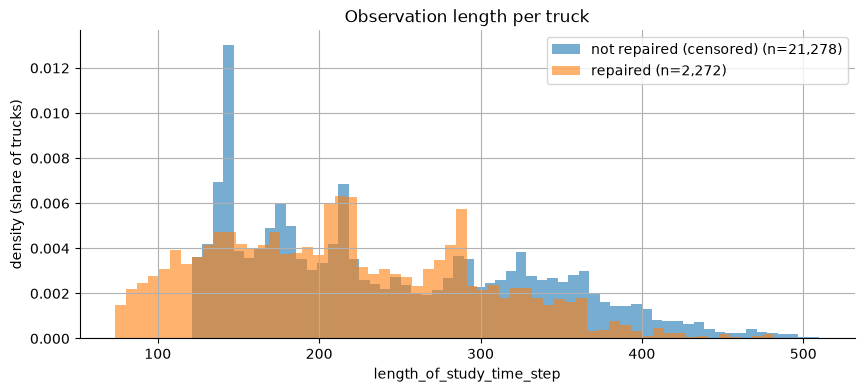

In [19]:
# How long were trucks observed? Repaired vs. not repaired
fig, ax = plt.subplots()
for value, label in [(0, "not repaired (censored)"), (1, "repaired")]:
    data = train_tte.loc[train_tte["in_study_repair"] == value, "length_of_study_time_step"]
    ax.hist(data, bins=60, alpha=0.6, density=True, label=f"{label} (n={len(data):,})")
ax.set_xlabel("length_of_study_time_step")
ax.set_ylabel("density (share of trucks)")
ax.set_title("Observation length per truck")
ax.legend()
save_figure(fig, "study_length")
plt.show()

**`density=True`** scales both histograms so that their areas are equal. Without it the
21,278 censored trucks would hide the 2,272 repaired ones. Read the shapes, not the heights.

## 6. Validation labels (classes 0–4)

The class belongs to the **last readout** of every validation truck. That last readout was
**chosen at random** by SCANIA to simulate "today" *(challenge description)*.

| Class | Time until repair |
|-------|-------------------|
| 0 | more than 48 |
| 1 | 48 to 24 |
| 2 | 24 to 12 |
| 3 | 12 to 6 |
| 4 | 6 to 0 |

*(paper)*: 4,910 / 16 / 14 / 30 / 76 trucks in classes 0 / 1 / 2 / 3 / 4.

In [20]:
class_counts = val_labels["class_label"].value_counts().sort_index()
class_table = pd.DataFrame(
    {"trucks": class_counts, "percent": class_counts / class_counts.sum() * 100}
)
display(class_table)

positive_share = (val_labels["class_label"] >= 1).mean() * 100
print(f"Question 1 (binary: class >= 1): {positive_share:.2f} % positives")
print(
    "-> a model that always says 'no repair' is right for "
    f"{100 - positive_share:.2f} % of the trucks and useless."
)

,trucks,percent
class_label,,
0,4910,97.30
1,16,0.32
2,14,0.28
3,30,0.59
4,76,1.51


Question 1 (binary: class >= 1): 2.70 % positives
-> a model that always says 'no repair' is right for 97.30 % of the trucks and useless.


saved reports/figures/01_eda_scania_validation_classes.png


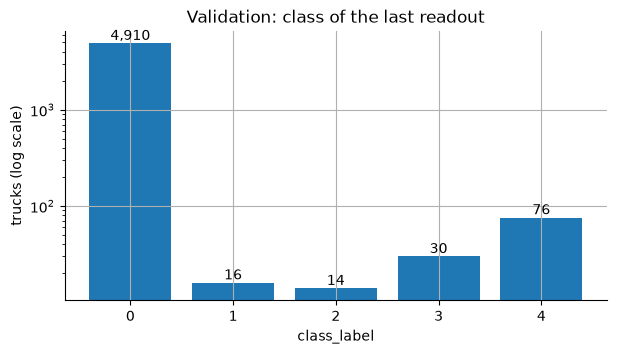

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(class_counts.index.astype(str), class_counts.values)
ax.set_yscale("log")  # log scale: otherwise classes 1-4 are invisible next to class 0
ax.set_xlabel("class_label")
ax.set_ylabel("trucks (log scale)")
ax.set_title("Validation: class of the last readout")
for x, y in zip(class_counts.index.astype(str), class_counts.values, strict=True):
    ax.text(x, y, f"{y:,}", ha="center", va="bottom")
save_figure(fig, "validation_classes")
plt.show()

## 7. Time: `time_step` and readouts per truck

`time_step` = number of time units the truck (and Component X) has been in use when the
readout was taken *(challenge description)*. It is a **decimal number** – a time, not a
readout counter. Readouts are **sporadic and uneven** *(challenge description)*.

In [22]:
ts = train_readouts["time_step"]
print("dtype:", ts.dtype, "| min:", ts.min(), "| max:", ts.max())
print("share of non-integer time steps:", f"{(ts % 1 != 0).mean() * 100:.1f} %")

dtype: float64 | min: 0.0 | max: 507.4
share of non-integer time steps: 79.8 %


count   23,550.00
mean        47.66
std         27.41
min          5.00
25%         28.00
50%         43.00
75%         64.00
max        303.00
dtype: float64

saved reports/figures/01_eda_scania_readouts_per_truck.png


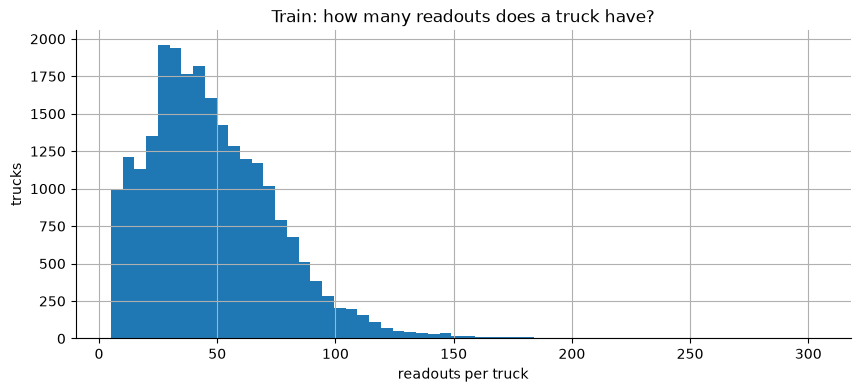

In [23]:
# Readouts per truck: groupby + size (like SQL: SELECT vehicle_id, COUNT(*) GROUP BY vehicle_id)
readouts_per_truck = train_readouts.groupby("vehicle_id").size()
display(readouts_per_truck.describe())

fig, ax = plt.subplots()
ax.hist(readouts_per_truck, bins=60)
ax.set_xlabel("readouts per truck")
ax.set_ylabel("trucks")
ax.set_title("Train: how many readouts does a truck have?")
save_figure(fig, "readouts_per_truck")
plt.show()

In [24]:
# Is time_step increasing inside each truck? (sort order of the file)
is_sorted = train_readouts.groupby("vehicle_id")["time_step"].apply(
    lambda s: s.is_monotonic_increasing
)
check(
    is_sorted.all(),
    f"time_step increases inside every truck ({(~is_sorted).sum()} trucks not sorted)",
)

# Sort once explicitly - never rely on file order
train_readouts = train_readouts.sort_values(["vehicle_id", "time_step"], ignore_index=True)

OK   time_step increases inside every truck (0 trucks not sorted)


count   1,098,902.00
mean            4.87
std             5.13
min             0.20
25%             1.60
50%             4.40
75%             6.20
max           387.80
Name: time_step, dtype: float64

saved reports/figures/01_eda_scania_readout_gaps.png


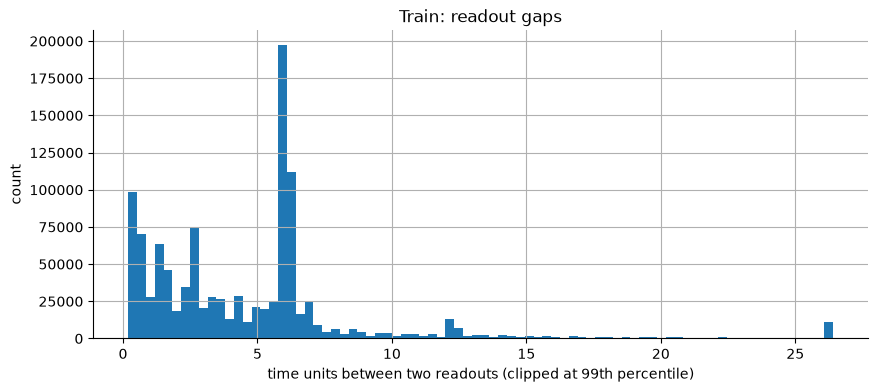

In [25]:
# Gaps between two readouts of the same truck: diff() inside each group
gaps = train_readouts.groupby("vehicle_id")["time_step"].diff().dropna()
display(gaps.describe())

fig, ax = plt.subplots()
ax.hist(
    gaps.clip(upper=gaps.quantile(0.99)), bins=80
)  # clip: cut the 1 % extreme values for readability
ax.set_xlabel("time units between two readouts (clipped at 99th percentile)")
ax.set_ylabel("count")
ax.set_title("Train: readout gaps")
save_figure(fig, "readout_gaps")
plt.show()

**Why the gaps matter:** class 4 means "repair within 6 time units". If trucks typically send
a readout only every 10–20 units, many trucks have **no** readout inside the last 6 units –
class 4 can only appear for some of them. Compare the median gap with the class windows.

In [26]:
# Last readout of each truck vs. the end of the study (L).
# A readout after L would be impossible -> data error.
last_t = train_readouts.groupby("vehicle_id")["time_step"].max().rename("last_time_step")
study = train_tte.set_index("vehicle_id").join(last_t)
study["gap_to_end"] = study["length_of_study_time_step"] - study["last_time_step"]
check((study["gap_to_end"] >= 0).all(), "no readout after the end of the study")
study.groupby("in_study_repair")["gap_to_end"].describe()

OK   no readout after the end of the study


,count,mean,std,min,25%,50%,75%,max
in_study_repair,,,,,,,,
0,"21,278.00",5.77,11.88,0.20,0.80,2.20,5.20,324.60
1,"2,272.00",3.87,11.76,0.20,0.60,1.80,4.00,260.00


saved reports/figures/01_eda_scania_timelines.png


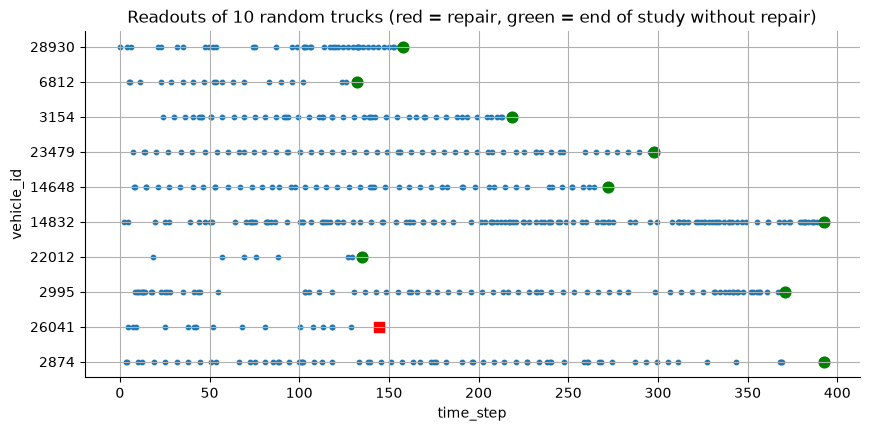

In [27]:
# Timeline of 10 random trucks: one dot per readout,
# red square = repair, green circle = end of study without repair
sample_ids = RNG.choice(train_tte["vehicle_id"].to_numpy(), size=10, replace=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
for row, vid in enumerate(sample_ids):
    times = train_readouts.loc[train_readouts["vehicle_id"] == vid, "time_step"]
    ax.scatter(times, [row] * len(times), s=10, color="tab:blue")
    end = study.loc[vid]
    marker, color = ("s", "red") if end["in_study_repair"] == 1 else ("o", "green")
    ax.scatter(end["length_of_study_time_step"], row, marker=marker, s=60, color=color)
ax.set_yticks(range(len(sample_ids)), [str(v) for v in sample_ids])
ax.set_xlabel("time_step")
ax.set_ylabel("vehicle_id")
ax.set_title("Readouts of 10 random trucks (red = repair, green = end of study without repair)")
save_figure(fig, "timelines")
plt.show()

## 8. Missing values

*(paper)*: less than 1 % missing per column. We check per **column**, per **row**, per
**truck** – three different questions:

- per column → which features need imputation?
- per row → are there "empty" readouts?
- per truck → are some trucks systematically incomplete?

In [28]:
missing_by_column = (
    train_readouts[feature_columns].isna().mean().mul(100).sort_values(ascending=False)
)
print(f"columns with missing values: {(missing_by_column > 0).sum()} of {len(feature_columns)}")
print(f"maximum per column: {missing_by_column.max():.3f} %")
check(missing_by_column.max() < 1, "matches the paper: < 1 % missing per column")
missing_by_column.head(10)

columns with missing values: 104 of 105
maximum per column: 0.858 %
OK   matches the paper: < 1 % missing per column


291_0    0.86
291_10   0.86
291_9    0.86
291_8    0.86
291_2    0.86
291_4    0.86
291_5    0.86
291_7    0.86
291_6    0.86
291_1    0.86
dtype: float64

saved reports/figures/01_eda_scania_missing_per_column.png


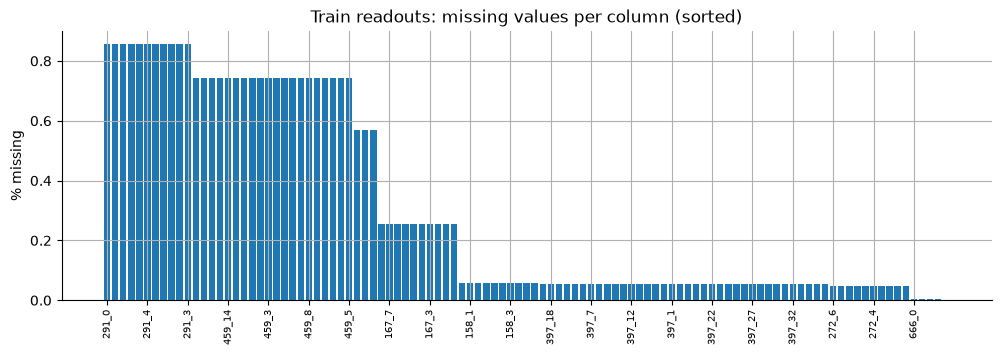

In [29]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(missing_by_column)), missing_by_column.values)
ax.set_xticks(
    range(len(missing_by_column))[::5], missing_by_column.index[::5], rotation=90, fontsize=7
)
ax.set_ylabel("% missing")
ax.set_title("Train readouts: missing values per column (sorted)")
save_figure(fig, "missing_per_column")
plt.show()

In [30]:
# Per row: how many of the 105 features are missing in one readout?
missing_per_row = train_readouts[feature_columns].isna().sum(axis=1)  # axis=1 -> along the columns
print(missing_per_row.value_counts().sort_index().head(10))

# Do missing values come in blocks, i.e. whole histograms missing together?
for var, cols in HISTOGRAMS.items():
    block = train_readouts[cols].isna()
    print(
        f"histogram {var}: rows with some bins missing {block.any(axis=1).sum():>6,} "
        f"| all bins missing {block.all(axis=1).sum():>6,}"
    )

0     1099971
1          15
2           6
3        6076
4          34
10       2713
11       4253
12          1
13        166
14         77
Name: count, dtype: int64
histogram 158: rows with some bins missing    648 | all bins missing    648
histogram 167: rows with some bins missing  2,862 | all bins missing  2,862
histogram 272: rows with some bins missing    525 | all bins missing    525
histogram 291: rows with some bins missing  9,628 | all bins missing  9,628
histogram 397: rows with some bins missing    610 | all bins missing    610
histogram 459: rows with some bins missing  8,353 | all bins missing  8,353


In [31]:
# Per truck: share of readouts with at least one missing value
row_has_missing = missing_per_row > 0
missing_per_truck = row_has_missing.groupby(train_readouts["vehicle_id"]).mean()
print(f"trucks with at least one incomplete readout: {(missing_per_truck > 0).mean() * 100:.1f} %")

# Are repaired trucks more often incomplete? (a missing value can carry information!)
compare = (
    missing_per_truck.rename("share_incomplete")
    .to_frame()
    .join(train_tte.set_index("vehicle_id")["in_study_repair"])
)
compare.groupby("in_study_repair")["share_incomplete"].mean()

trucks with at least one incomplete readout: 29.7 %


in_study_repair
0   0.02
1   0.02
Name: share_incomplete, dtype: float64

## 9. Counters: do they only grow?

Counters are "mostly cumulative" *(paper)*, like the odometer of a car. The paper also
mentions that counters **can be reset** when the ECU software is updated. A reset shows up
as a **negative difference** between two readouts. This matters for feature engineering:
the change per time unit (Δ / Δt) is wrong across a reset.

In [32]:
diffs = train_readouts.groupby("vehicle_id")[COUNTERS].diff()
negative = diffs < 0
reset_stats = pd.DataFrame(
    {
        "negative_steps": negative.sum(),
        "trucks_affected": negative.groupby(train_readouts["vehicle_id"]).any().sum(),
    }
)
reset_stats["percent_of_steps"] = reset_stats["negative_steps"] / diffs.notna().sum() * 100
reset_stats.sort_values("negative_steps", ascending=False)

,negative_steps,trucks_affected,percent_of_steps
171_0,7,7,0.00
100_0,0,0,0.00
309_0,0,0,0.00
370_0,0,0,0.00
427_0,0,0,0.00
666_0,0,0,0.00
835_0,0,0,0.00
837_0,0,0,0.00


saved reports/figures/01_eda_scania_counter_over_time.png


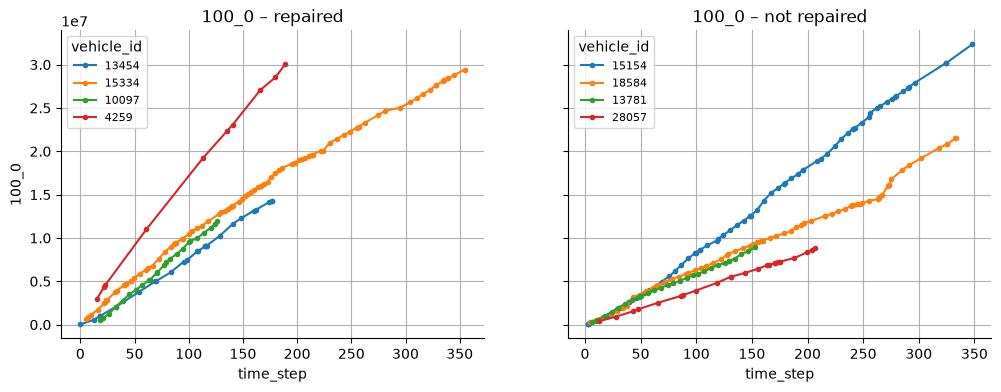

In [33]:
# Counter values over time for 4 repaired and 4 not repaired trucks
repaired_ids = RNG.choice(
    train_tte.loc[train_tte["in_study_repair"] == 1, "vehicle_id"], 4, replace=False
)
healthy_ids = RNG.choice(
    train_tte.loc[train_tte["in_study_repair"] == 0, "vehicle_id"], 4, replace=False
)
counter = COUNTERS[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, ids, title in [(axes[0], repaired_ids, "repaired"), (axes[1], healthy_ids, "not repaired")]:
    for vid in ids:
        truck = train_readouts[train_readouts["vehicle_id"] == vid]
        ax.plot(truck["time_step"], truck[counter], marker=".", label=str(vid))
    ax.set_title(f"{counter} – {title}")
    ax.set_xlabel("time_step")
    ax.legend(title="vehicle_id", fontsize=8)
axes[0].set_ylabel(counter)
save_figure(fig, "counter_over_time")
plt.show()

saved reports/figures/01_eda_scania_counter_correlation.png


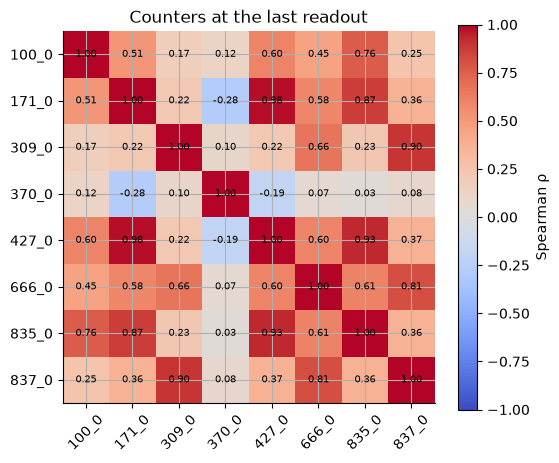

In [34]:
# Correlation between counters at the last readout of each truck
# Spearman = correlation of ranks: robust against outliers and non-linear but monotonic relations
last_readout = train_readouts.groupby("vehicle_id").tail(1).set_index("vehicle_id")
corr = last_readout[COUNTERS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(COUNTERS)), COUNTERS, rotation=45)
ax.set_yticks(range(len(COUNTERS)), COUNTERS)
for i in range(len(COUNTERS)):
    for j in range(len(COUNTERS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Counters at the last readout")
save_figure(fig, "counter_correlation")
plt.show()

*(paper)*: all counters are positively correlated. Strongly correlated counters mostly
measure **usage / age**: a truck that drove more has higher values everywhere. This is why
rates (change per time unit) are often more informative than raw cumulative values.

## 10. Histograms

A histogram row counts how much happened in each bin (condition range) **up to that
readout**. Two questions:

1. Do the bin values also accumulate over time (like counters)?
2. Does the **shape** (share per bin) differ for trucks close to a repair?

To compare trucks of different age, we turn counts into **shares**: each bin divided by the
sum of all bins of that histogram (row-wise normalisation).

In [35]:
var = "167" if "167" in HISTOGRAMS else next(iter(HISTOGRAMS))
cols = HISTOGRAMS[var]

totals = train_readouts[cols].sum(axis=1)  # total of the histogram per readout
total_diff = totals.groupby(train_readouts["vehicle_id"]).diff()
print(
    f"histogram {var}: total decreases in {(total_diff < 0).mean() * 100:.2f} % of steps "
    "-> close to 0 % means the histogram is cumulative"
)

histogram 167: total decreases in 0.05 % of steps -> close to 0 % means the histogram is cumulative


saved reports/figures/01_eda_scania_histogram_167_shape.png


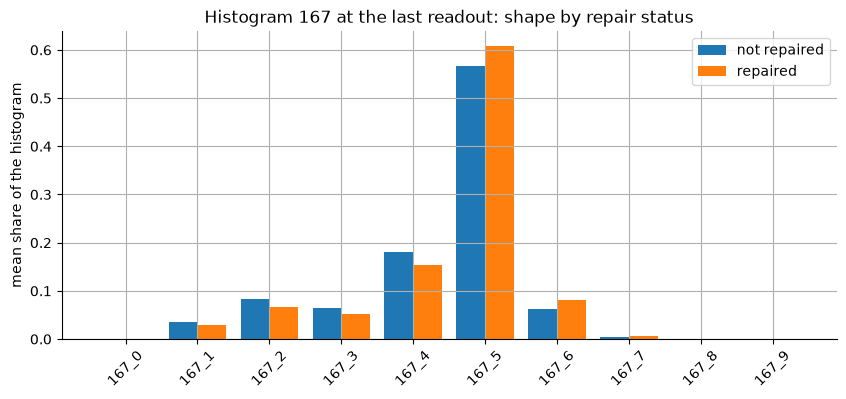

In [36]:
def histogram_shares(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    # Divide every bin by the row total -> shares between 0 and 1 that sum to 1
    total = df[cols].sum(axis=1).replace(0, np.nan)  # avoid division by zero
    return df[cols].div(total, axis=0)


# Last readout of every truck + repair flag
last = last_readout.join(train_tte.set_index("vehicle_id")["in_study_repair"])
shares = histogram_shares(last, cols)
mean_shares = shares.groupby(last["in_study_repair"]).mean().T  # rows = bins, columns = 0/1

fig, ax = plt.subplots()
x = np.arange(len(cols))
ax.bar(x - 0.2, mean_shares[0], width=0.4, label="not repaired")
ax.bar(x + 0.2, mean_shares[1], width=0.4, label="repaired")
ax.set_xticks(x, cols, rotation=45)
ax.set_ylabel("mean share of the histogram")
ax.set_title(f"Histogram {var} at the last readout: shape by repair status")
ax.legend()
save_figure(fig, f"histogram_{var}_shape")
plt.show()

**Careful with the interpretation:** the last readout of a repaired truck is close to the
repair, the last readout of a censored truck is just "end of study". A difference in shape is
a hint for feature engineering, **not** proof of a cause. And the variables are anonymised –
we must not invent a physical meaning.

saved reports/figures/01_eda_scania_histogram_shapes_all.png


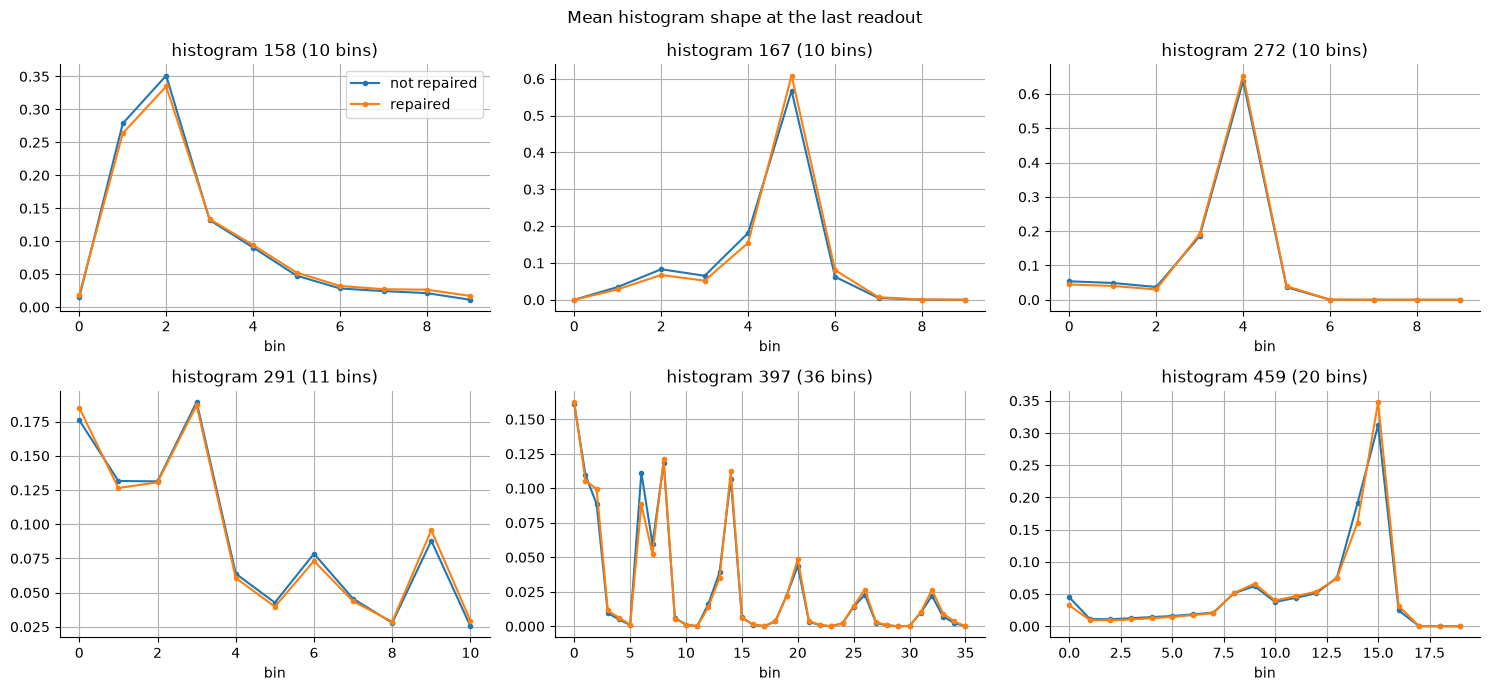

In [37]:
# Overview: same comparison for all 6 histograms in one figure
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (var, cols) in zip(axes.ravel(), HISTOGRAMS.items(), strict=False):  # 6 histograms, 6 axes
    s = histogram_shares(last, cols).groupby(last["in_study_repair"]).mean().T
    x = np.arange(len(cols))
    ax.plot(x, s[0], marker=".", label="not repaired")
    ax.plot(x, s[1], marker=".", label="repaired")
    ax.set_title(f"histogram {var} ({len(cols)} bins)")
    ax.set_xlabel("bin")
axes[0, 0].legend()
fig.suptitle("Mean histogram shape at the last readout")
fig.tight_layout()
save_figure(fig, "histogram_shapes_all")
plt.show()

## 11. Specifications (categorical master data)

8 categorical columns `Spec_0 … Spec_7`, no missing values *(paper)*. Three questions:

1. How many categories (**cardinality**) does each column have? → one-hot encoding size
2. Does the repair rate differ between categories? → possible signal
3. Are the distributions the same in train, validation and test? → otherwise **data drift**

In [38]:
spec_columns = [c for c in train_spec.columns if c != "vehicle_id"]
cardinality = pd.DataFrame(
    {
        "train": train_spec[spec_columns].nunique(),
        "validation": val_spec[spec_columns].nunique(),
        "test": test_spec[spec_columns].nunique(),
        "missing_train": train_spec[spec_columns].isna().sum(),
    }
)
cardinality

,train,validation,test,missing_train
Spec_0,3,3,3,0
Spec_1,29,29,29,0
Spec_2,21,20,19,0
Spec_3,4,4,4,0
Spec_4,2,2,2,0
Spec_5,5,5,5,0
Spec_6,17,16,17,0
Spec_7,9,9,9,0


In [39]:
# Categories that appear in validation/test but never in train -> the encoder must handle them
for col in spec_columns:
    unseen = (set(val_spec[col]) | set(test_spec[col])) - set(train_spec[col])
    if unseen:
        print(f"{col}: categories not in train -> {sorted(unseen)}")
print("-> OneHotEncoder(handle_unknown='ignore') will be needed if anything is listed above")

Spec_1: categories not in train -> ['Cat29']
Spec_6: categories not in train -> ['Cat14', 'Cat16']
-> OneHotEncoder(handle_unknown='ignore') will be needed if anything is listed above


In [40]:
# Repair rate per category (only categories with >= 100 trucks, otherwise the rate is noise)
spec_target = train_spec.merge(train_tte[["vehicle_id", "in_study_repair"]], on="vehicle_id")
for col in spec_columns[:3]:  # first three columns; change the slice to see more
    rate = (
        spec_target.groupby(col)["in_study_repair"]
        .agg(trucks="size", repair_rate="mean")
        .query("trucks >= 100")
        .sort_values("repair_rate", ascending=False)
    )
    rate["repair_rate"] *= 100
    print(f"\n{col} (overall repair rate {spec_target['in_study_repair'].mean() * 100:.1f} %)")
    display(rate.head(8))


Spec_0 (overall repair rate 9.6 %)


,trucks,repair_rate
Spec_0,,
Cat0,19221,10.29
Cat1,4291,6.83



Spec_1 (overall repair rate 9.6 %)


,trucks,repair_rate
Spec_1,,
Cat17,311,15.43
Cat5,541,13.68
Cat4,676,10.50
Cat1,13362,10.48
Cat2,935,10.37
Cat10,749,9.75
Cat13,860,9.30
Cat3,278,8.99



Spec_2 (overall repair rate 9.6 %)


,trucks,repair_rate
Spec_2,,
Cat5,545,19.82
Cat6,268,15.67
Cat13,182,14.29
Cat1,14352,10.30
Cat10,755,9.80
Cat2,2624,9.22
Cat3,812,8.37
Cat0,3255,5.71


saved reports/figures/01_eda_scania_spec_split_distribution.png


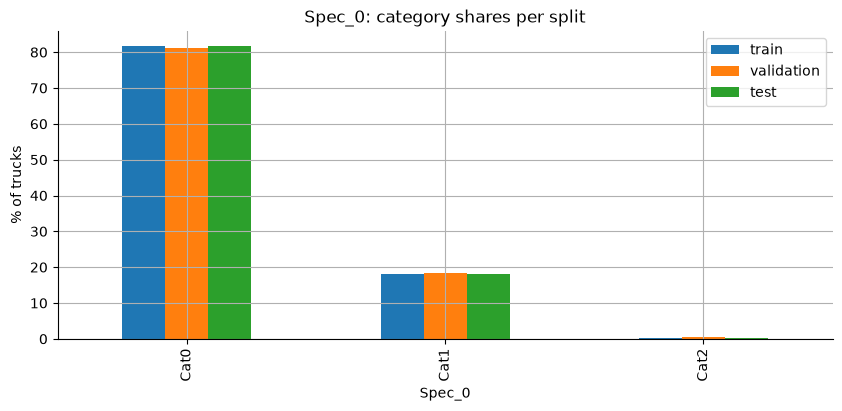

In [41]:
# Distribution of one spec column in the three splits (normalised -> comparable)
col = spec_columns[0]
dist = (
    pd.DataFrame(
        {
            "train": train_spec[col].value_counts(normalize=True),
            "validation": val_spec[col].value_counts(normalize=True),
            "test": test_spec[col].value_counts(normalize=True),
        }
    )
    .fillna(0)
    .sort_values("train", ascending=False)
    .head(12)
)

ax = (dist * 100).plot.bar(figsize=(10, 4))
ax.set_ylabel("% of trucks")
ax.set_title(f"{col}: category shares per split")
save_figure(ax.figure, "spec_split_distribution")
plt.show()

## 12. Preview: classes per training readout (censoring)

This is **exploration only** – the real implementation follows tomorrow in
`src/failsense/data/labels.py` with tests.

For every training readout: `d = length_of_study_time_step − time_step` (time until the end
of the study).

| Truck | `d` | Class |
|-------|-----|-------|
| repaired | > 48 | 0 |
| repaired | 48–24 / 24–12 / 12–6 / 6–0 | 1 / 2 / 3 / 4 |
| not repaired | > 48 | 0 (the repair is at least 48 away) |
| not repaired | ≤ 48 | **unknown (censored)** → not used for training |

The window borders are written as "48 to 24" etc. in the challenge description; whether 48
itself belongs to class 0 or 1 is **not** specified. Here we use `(24, 48]` → class 1, i.e.
`d ≤ 48` is inside the window. Tomorrow this choice is written down and tested.

In [42]:
readouts = train_readouts[["vehicle_id", "time_step"]].merge(
    train_tte, on="vehicle_id", how="left", validate="many_to_one"
)  # validate: pandas raises an error if the join is not many-to-one (like a FK check)
readouts["d"] = readouts["length_of_study_time_step"] - readouts["time_step"]

# Class from d for repaired trucks: pd.cut puts every value into a window (bin)
borders = [-np.inf, 6, 12, 24, 48, np.inf]  # right edges inclusive: (24, 48] -> class 1
labels_for_window = [4, 3, 2, 1, 0]
readouts["class_preview"] = pd.cut(readouts["d"], bins=borders, labels=labels_for_window).astype(
    "Int64"
)

# Censored trucks: d <= 48 is unknown
unknown = (readouts["in_study_repair"] == 0) & (readouts["d"] <= 48)
readouts.loc[unknown, "class_preview"] = pd.NA

preview = readouts["class_preview"].value_counts(dropna=False).sort_index()
display(pd.DataFrame({"readouts": preview, "percent": preview / len(readouts) * 100}))
check((readouts["d"] >= 0).all(), "d is never negative")

,readouts,percent
class_preview,,
0,893575,79.61
1,12503,1.11
2,6179,0.55
3,3200,0.29
4,3858,0.34
<NA>,203137,18.10


OK   d is never negative


**What to look at:**

- How many readouts are **unknown** (`<NA>`) – data we lose because of censoring.
- How few readouts fall into classes 1–4 – the real imbalance at readout level.
- Compare with the validation classes in section 6 (one readout per truck there!).

saved reports/figures/01_eda_scania_last_readout_train_vs_validation.png


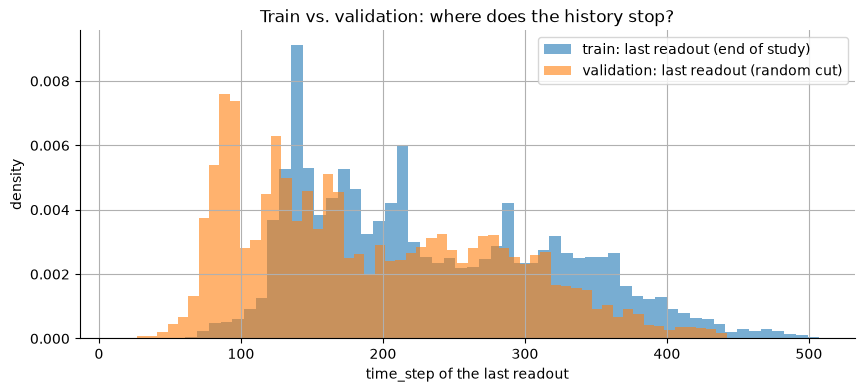

In [43]:
# Validation: last readout per truck - how far into the life of the truck was the random cut?
val_last_t = val_readouts.groupby("vehicle_id")["time_step"].max()
train_last_t = train_readouts.groupby("vehicle_id")["time_step"].max()

fig, ax = plt.subplots()
ax.hist(train_last_t, bins=60, alpha=0.6, density=True, label="train: last readout (end of study)")
ax.hist(val_last_t, bins=60, alpha=0.6, density=True, label="validation: last readout (random cut)")
ax.set_xlabel("time_step of the last readout")
ax.set_ylabel("density")
ax.set_title("Train vs. validation: where does the history stop?")
ax.legend()
save_figure(fig, "last_readout_train_vs_validation")
plt.show()

## 13. Leakage checklist (state after this EDA)

| Risk | Status | Where it is enforced later |
|------|--------|----------------------------|
| Same truck in two splits | checked in section 3 | `tests/test_leakage.py`, `data/schema.py` |
| Label columns as features (`length_of_study_time_step`, `in_study_repair`, `d`, class) | never in `feature_columns` | `tests/test_leakage.py` |
| `vehicle_id` as feature | excluded (`FORBIDDEN_FEATURES`) | `models/pipeline.py`, `tests/test_leakage.py` |
| Information from the future | features from readouts ≤ t only | `features/build.py`, `tests/test_leakage.py` |
| Looking at test labels | not loaded in this notebook | used once at the end; training entry points read only the train split (`tests/test_leakage.py`) |

All leakage tests carry the pytest marker `leakage`: `make leakage` (`uv run pytest -m leakage`).

## 14. Findings (measured on 26.10.2026)

1. **Tables and keys:** all primary/foreign key checks pass; 23,550 / 5,046 / 5,045 trucks; readouts unique per (vehicle_id, time_step).
2. **Split overlap:** 0 trucks shared between train, validation and test. IDs come from one fleet (0–33,643) split at random by truck → `vehicle_id` is never a feature.
3. **Repaired trucks:** 2,272 of 23,550 = 9.65 % (paper: same). Validation: 97.30 % class 0; classes 1/2/3/4 = 16/14/30/76 trucks → only 2.70 % positives; per-class metrics on validation are very noisy.
4. **Time:** `time_step` is decimal (79.8 % non-integer), max 507.4. Median 43 readouts per truck; median gap 4.4 time units → the class-4 window (6 units) holds about one readout. Last readout is close to the end of the study (median gap 2.2 censored / 1.8 repaired).
5. **Missing values:** max 0.86 % per column; histograms are missing as whole blocks; 29.7 % of trucks have at least one incomplete readout; same share for repaired and not repaired (≈ 2 %) → missingness carries no signal.
6. **Counter resets:** only 7 negative steps (counter 171_0, 7 trucks) in 1.1 M readouts → counters are cumulative. The 7 negative steps are kept as they are (decision 05.11: no clipping, see `docs/problem_framing.md` §6).
7. **Histograms:** cumulative (total decreases in 0.05 % of steps). Mean shape at the last readout is almost identical for repaired and not repaired trucks → weak static signal; changes over time are more promising.
8. **Specifications:** no missing values; categories in val/test not seen in train (Spec_1: Cat29; Spec_6: Cat14, Cat16) → `OneHotEncoder(handle_unknown="ignore")`. Repair rate differs by category (Spec_2: 19.8 % vs 5.7 %).
9. **Readout classes (preview):** 79.61 % class 0, 2.29 % classes 1–4, 18.10 % unknown (censored). Validation histories stop much earlier than training histories → training samples must imitate the random cut-off.

**What came after the EDA** (not part of this notebook; measured on the training split, the test split is untouched): labels and cut-off sampling (27.10), the data contract (29.10), engineered features, imbalance handling, outliers and the `time_step` check (30.10 tasks, caught up 05.11). Results and decisions: [`docs/problem_framing.md`](../docs/problem_framing.md) (v0.6), numbers in the README section "Results so far".
